# Laboratorium 3 - Prognozowanie szeregów czasowych

## 1. Instalacja i import

In [1]:
!pip -q install torch numpy matplotlib

In [2]:
import numpy as np, torch, torch.nn as nn, matplotlib.pyplot as plt
torch.manual_seed(0); np.random.seed(0)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Urządzenie:', DEVICE)

Urządzenie: cpu


## 2. Dane: dzienna sprzedaż

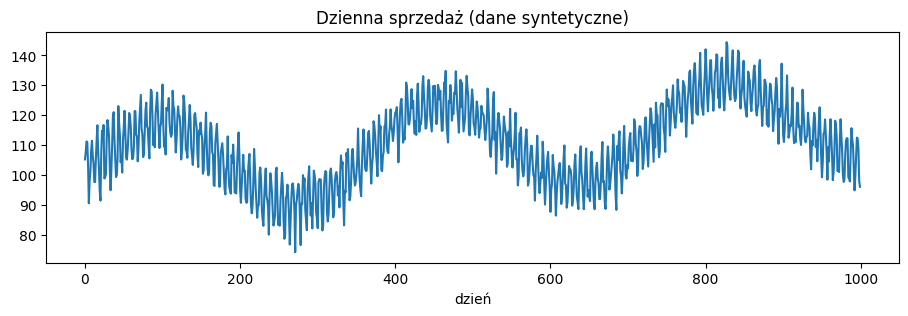

In [3]:
def generuj_sprzedaz(n=1000):
    t = np.arange(n)
    trend = 0.02*t
    tygodniowa = 8*np.sin(2*np.pi*t/7)
    roczna = 15*np.sin(2*np.pi*t/365)
    szum = np.random.randn(n)*3
    return (100 + trend + tygodniowa + roczna + szum).astype(np.float32)

seria = generuj_sprzedaz(1000)
plt.figure(figsize=(11,3)); plt.plot(seria)
plt.title('Dzienna sprzedaż (dane syntetyczne)'); plt.xlabel('dzień'); plt.show()

## 3. Podział chronologiczny i standaryzacja

Trening: 0..700  Walidacja: 700..850  Test: 850..1000
mu = 106.96, sd = 12.00


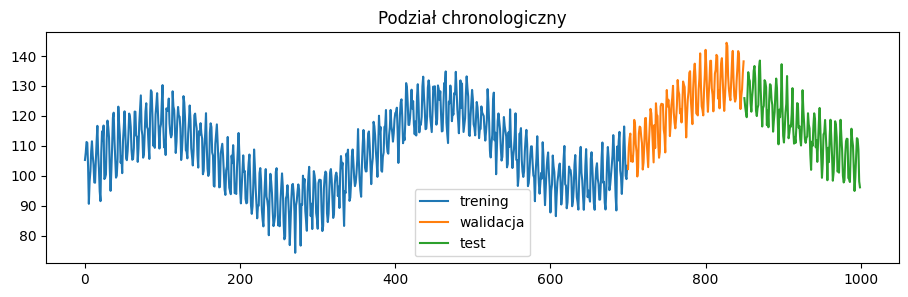

In [4]:
n = len(seria); i_tr = int(0.7*n); i_va = int(0.85*n)
mu, sd = seria[:i_tr].mean(), seria[:i_tr].std()
s = (seria - mu) / sd
print(f'Trening: 0..{i_tr}  Walidacja: {i_tr}..{i_va}  Test: {i_va}..{n}')
print(f'mu = {mu:.2f}, sd = {sd:.2f}')

plt.figure(figsize=(11,3))
plt.plot(range(0, i_tr), seria[:i_tr], label='trening')
plt.plot(range(i_tr, i_va), seria[i_tr:i_va], label='walidacja')
plt.plot(range(i_va, n), seria[i_va:], label='test')
plt.legend(); plt.title('Podział chronologiczny'); plt.show()

## 4. Okna wejście-cel

In [5]:
OKNO = 28

def zrob_okna(s, okno, i_lo, i_hi):
    X, Y = [], []
    for i in range(max(okno, i_lo), i_hi):
        X.append(s[i-okno:i]); Y.append(s[i])
    return (torch.tensor(np.array(X, np.float32)[..., None]).to(DEVICE),
            torch.tensor(np.array(Y, np.float32)[:, None]).to(DEVICE))

Xtr, Ytr = zrob_okna(s, OKNO, OKNO, i_tr)
Xva, Yva = zrob_okna(s, OKNO, i_tr, i_va)
Xte, Yte = zrob_okna(s, OKNO, i_va, n)
print('kształty:', tuple(Xtr.shape), tuple(Xva.shape), tuple(Xte.shape))

kształty: (672, 28, 1) (150, 28, 1) (150, 28, 1)


## 5. Model GRU i uczenie

najlepsza epoka: 36, val MSE: 0.0822
liczba parametrów: 3393


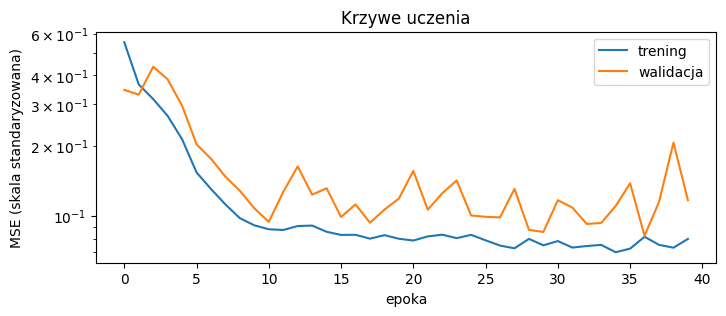

In [6]:
class ModelGRU(nn.Module):
    def __init__(self, hidden=32):
        super().__init__()
        self.rnn = nn.GRU(1, hidden, batch_first=True)
        self.fc = nn.Linear(hidden, 1)
    def forward(self, x):
        out, _ = self.rnn(x)
        return self.fc(out[:, -1, :])

def trenuj(model, epoki=40, lr=1e-2, batch=64, clip=None, dane=None, wypisz=True):
    Xtr_, Ytr_, Xva_, Yva_ = dane if dane is not None else (Xtr, Ytr, Xva, Yva)
    model = model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    L = nn.MSELoss()
    best, best_state, best_ep = float('inf'), None, 0
    h_tr, h_va = [], []
    for ep in range(epoki):
        model.train(); perm = torch.randperm(len(Xtr_)); straty = []
        for i in range(0, len(Xtr_), batch):
            idx = perm[i:i+batch]; opt.zero_grad()
            loss = L(model(Xtr_[idx]), Ytr_[idx]); loss.backward()
            if clip is not None:
                torch.nn.utils.clip_grad_norm_(model.parameters(), clip)
            opt.step(); straty.append(loss.item())
        model.eval()
        with torch.no_grad(): v = L(model(Xva_), Yva_).item()
        h_tr.append(np.mean(straty)); h_va.append(v)
        if v < best:
            best, best_ep = v, ep
            best_state = {k: t.clone() for k, t in model.state_dict().items()}
    model.load_state_dict(best_state)
    if wypisz: print(f'najlepsza epoka: {best_ep}, val MSE: {best:.4f}')
    return model, h_tr, h_va

torch.manual_seed(0)
model, h_tr, h_va = trenuj(ModelGRU(32))
print('liczba parametrów:', sum(p.numel() for p in model.parameters()))

plt.figure(figsize=(8,3))
plt.plot(h_tr, label='trening'); plt.plot(h_va, label='walidacja')
plt.yscale('log'); plt.xlabel('epoka'); plt.ylabel('MSE (skala standaryzowana)')
plt.title('Krzywe uczenia'); plt.legend(); plt.show()

## 6. Prognoza jednokrokowa na teście

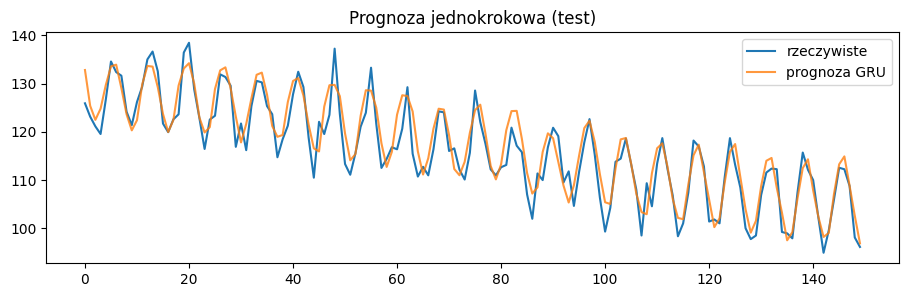

In [7]:
def mae(a, b):  return float(np.mean(np.abs(a - b)))
def rmse(a, b): return float(np.sqrt(np.mean((a - b)**2)))

model.eval()
with torch.no_grad(): pred = model(Xte).cpu().numpy().ravel()
pred_raw = pred*sd + mu
true_raw = Yte.cpu().numpy().ravel()*sd + mu

plt.figure(figsize=(11,3))
plt.plot(true_raw, label='rzeczywiste'); plt.plot(pred_raw, label='prognoza GRU', alpha=0.8)
plt.legend(); plt.title('Prognoza jednokrokowa (test)'); plt.show()

## 7. Porównanie z baseline'ami (jednokrokowo)

In [8]:
tgt = np.arange(i_va, n)
naive    = seria[tgt-1]
seasonal = seria[tgt-7]
ma = np.array([seria[i-OKNO:i].mean() for i in tgt], np.float32)

print(f'{"metoda":16s}  MAE    RMSE')
for nazwa, p in [('GRU', pred_raw), ('naiwny (t-1)', naive),
                 ('sezonowy (t-7)', seasonal), ('śr. ruchoma', ma)]:
    print(f'{nazwa:16s} {mae(true_raw, p):5.2f}  {rmse(true_raw, p):5.2f}')
print(f'{"granica szumu":16s} {3*np.sqrt(2/np.pi):5.2f}  {3.0:5.2f}')

metoda            MAE    RMSE
GRU               2.91   3.54
naiwny (t-1)      5.44   6.51
sezonowy (t-7)    3.21   4.07
śr. ruchoma       5.80   6.84
granica szumu     2.39   3.00


## 8. Ocena prognozy wielokrokowej na teście

liczba startów: 10
metoda      MAE    RMSE   (H = 14)
GRU         3.88   4.75
sezonowy    3.52   4.42
naiwny     10.09  11.85


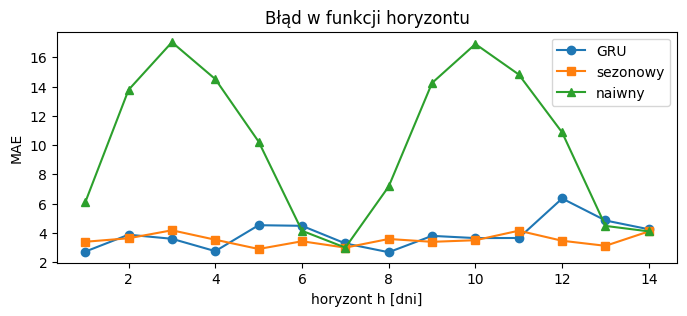

In [9]:
def rollout(model, s, start, H, okno):
    hist = list(s[start-okno:start]); wyn = []
    model.eval()
    with torch.no_grad():
        for _ in range(H):
            x = torch.tensor(np.array(hist[-okno:], np.float32).reshape(1, okno, 1)).to(DEVICE)
            y = model(x).item(); wyn.append(y); hist.append(y)
    return np.array(wyn)

def ocena_wielokrokowa(model, okno, H=14):
    bledy = {'GRU': [], 'sezonowy': [], 'naiwny': []}
    for t0 in range(i_va, n - H + 1, H):
        prawda = seria[t0:t0+H]
        prognozy = {
            'GRU': rollout(model, s, t0, H, okno)*sd + mu,
            'sezonowy': np.array([seria[t0 - 7 + (h % 7)] for h in range(H)]),
            'naiwny': np.full(H, seria[t0-1]),
        }
        for k, p in prognozy.items(): bledy[k].append(p - prawda)
    return {k: np.array(v) for k, v in bledy.items()}

H = 14
bledy = ocena_wielokrokowa(model, OKNO, H)
print('liczba startów:', len(bledy['GRU']))
print(f'{"metoda":10s}  MAE    RMSE   (H = {H})')
for k, e in bledy.items():
    print(f'{k:10s} {np.abs(e).mean():5.2f}  {np.sqrt((e**2).mean()):5.2f}')

plt.figure(figsize=(8,3))
for k, znak in [('GRU', 'o-'), ('sezonowy', 's-'), ('naiwny', '^-')]:
    plt.plot(range(1, H+1), np.abs(bledy[k]).mean(axis=0), znak, label=k)
plt.xlabel('horyzont h [dni]'); plt.ylabel('MAE'); plt.title('Błąd w funkcji horyzontu')
plt.legend(); plt.show()

## 9. Prognoza poza końcem danych

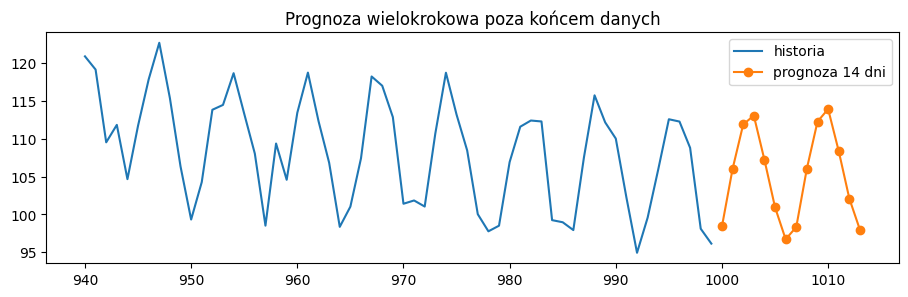

In [10]:
preds_raw = rollout(model, s, n, H, OKNO)*sd + mu
plt.figure(figsize=(11,3))
plt.plot(range(n-60, n), seria[n-60:], label='historia')
plt.plot(range(n, n+H), preds_raw, 'o-', label=f'prognoza {H} dni')
plt.legend(); plt.title('Prognoza wielokrokowa poza końcem danych'); plt.show()

## 10. Eksperyment: wpływ długości okna

In [11]:
def eksperyment(okno, ziarno, epoki=40):
    dane = (*zrob_okna(s, okno, okno, i_tr), *zrob_okna(s, okno, i_tr, i_va))
    Xte_, Yte_ = zrob_okna(s, okno, i_va, n)
    torch.manual_seed(ziarno)
    m, _, h_va_ = trenuj(ModelGRU(32), epoki=epoki, dane=dane, wypisz=False)
    m.eval()
    with torch.no_grad(): p = m(Xte_).cpu().numpy().ravel()*sd + mu
    y = Yte_.cpu().numpy().ravel()*sd + mu
    e = ocena_wielokrokowa(m, okno)['GRU']
    return min(h_va_), mae(y, p), float(np.abs(e).mean())

okna, ziarna = [3, 7, 28], [0, 1]
print(f'{"okno":>4s} {"ziarno":>6s} {"val MSE":>8s} {"MAE 1-krok":>11s} {"MAE 14-krok":>12s}')
wyniki = {}
for o in okna:
    for z in ziarna:
        wyniki[(o, z)] = eksperyment(o, z)
        v, m1, mH = wyniki[(o, z)]
        print(f'{o:4d} {z:6d} {v:8.4f} {m1:11.2f} {mH:12.2f}')

najlepsze = min(okna, key=lambda o: np.mean([wyniki[(o, z)][0] for z in ziarna]))
print('Najlepsze okno według walidacji:', najlepsze)

okno ziarno  val MSE  MAE 1-krok  MAE 14-krok
   3      0   0.2567        5.00         7.18
   3      1   0.2486        5.04         7.41
   7      0   0.0855        2.90         4.21
   7      1   0.0896        2.88         3.89
  28      0   0.0822        2.91         3.88
  28      1   0.0850        3.01         4.29
Najlepsze okno według walidacji: 28
